Step 1 — Load the data
5–10 minutesImport the necessary libraries and load your existing Banking77 dataset.
Requirements
- Convert the training partition into a pandas DataFrame.
- Inspect its first five rows.
- Display the column names and dataset shape.
- Make sure numerical label IDs can be mapped to human-readable intent names.

In [1]:
from datasets import load_dataset
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

d:\PROGRAMMING_PROJECTS\DS_RP_PROJECTS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = load_dataset("PolyAI/banking77")
# print(dataset[:5])

In [3]:
train_data = dataset['train']
test_data = dataset['test']

In [4]:
#Convert partitions into pandas dfs
df_tr = pd.DataFrame(train_data)
df_ts = pd.DataFrame(test_data)

In [5]:
df_tr.head()

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11


In [6]:
print('Column names:',df_tr.columns)
print(f'Train dataset shape:{df_tr.shape}')

Column names: Index(['text', 'label'], dtype='str')
Train dataset shape:(10003, 2)


In [7]:
df_tr.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    10003 non-null  str  
 1   label   10003 non-null  int64
dtypes: int64(1), str(1)
memory usage: 737.5 KB


    Step 2 — Class frequency analysis
    Objective
    Determine how many customer messages belong to each banking intent.
    Questions to answer
    - How many unique intent labels are present?
    - How many observations belong to each class?
    - Which five classes have the most observations?
    - Which five classes have the fewest observations?
    - Is the dataset reasonably balanced?

In [8]:
df_tr['text'].nunique()

10003

In [9]:
print('Count of unique labels:')
df_tr['label'].nunique()

Count of unique labels:


77

In [10]:
df_tr['label'].value_counts()

label
15    187
28    182
6     181
75    180
19    177
     ... 
41     82
18     61
10     59
72     41
23     35
Name: count, Length: 77, dtype: int64

In [11]:
df_tr['label'].value_counts().head()

label
15    187
28    182
6     181
75    180
19    177
Name: count, dtype: int64

In [12]:
df_tr['label'].value_counts().tail()

label
41    82
18    61
10    59
72    41
23    35
Name: count, dtype: int64

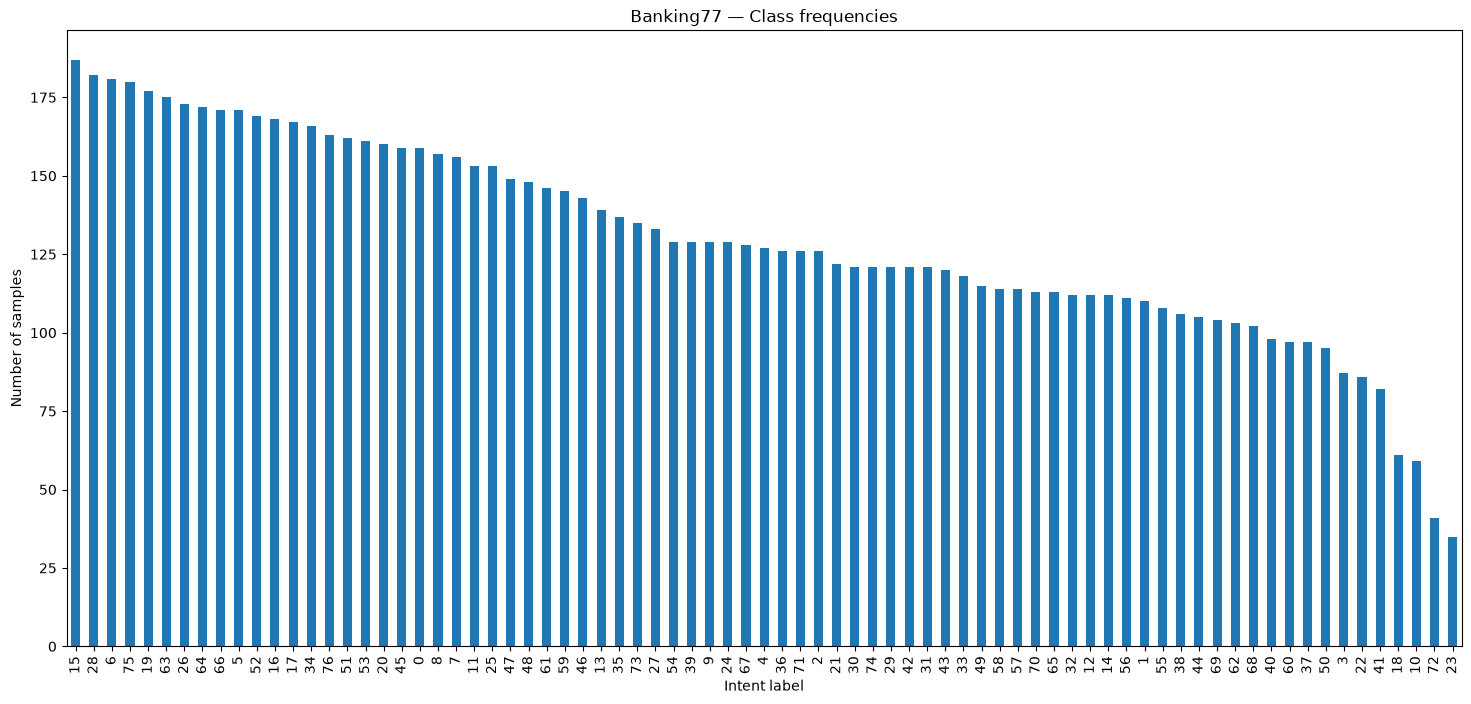

In [13]:
### Vizualize distribution
import matplotlib.pyplot as plt

counts = df_tr['label'].value_counts()
counts.plot(
    kind='bar',
    figsize=(18,8)
)
plt.xlabel('Intent label')
plt.ylabel('Number of samples')
plt.title('Banking77 — Class frequencies')
plt.show()
# fig, ax = plt.subplots(figsize=(7, 4))
# ax.hist(df_tr['label'], bins=50, edgecolor='black')
# ax.set_xlabel('label')
# ax.set_ylabel('count')
# ax.set_title('Distribution of amount')
# plt.tight_layout()
# plt.show()

    Step 3 — Investigate class imbalance
    10 minutesClass frequency tells you the number of samples in each class. Class imbalance analysis helps you interpret those numbers.

    Calculate the following:
    Metric	Your result
    Maximum class frequency	?
    Minimum class frequency	?
    Mean class frequency	?
    Median class frequency	?
    Maximum-to-minimum ratio	?

    The imbalance ratio can be calculated as:
    \[
    \text{Imbalance ratio}=
    \frac{\text{Largest class count}}
    {\text{Smallest class count}}
    \]

    Answer this question:
    Based on the class distribution, do we have sufficient evidence to describe the dataset as reasonably balanced or significantly imbalanced?

    There is no universal imbalance-ratio threshold. Explain your conclusion using the actual frequencies rather than relying on an arbitrary number.

    Do not apply oversampling or undersampling yet.

In [14]:
print(f'Duplicates count for text column:{df_tr['text'].duplicated().sum()}')
print(f'Missing values count for text column:{df_tr['text'].isna().sum()}')

Duplicates count for text column:0
Missing values count for text column:0


In [15]:
df_tr['label'].value_counts()
print('Class with the maximum frequency:',df_tr['label'].value_counts().idxmax())

Class with the maximum frequency: 15


In [16]:
print('Class with the minimum frequency:',df_tr['label'].value_counts().idxmin())

Class with the minimum frequency: 23


In [17]:
print(df_tr['label'].value_counts().mean())

129.9090909090909


In [18]:
print(df_tr['label'].value_counts().median())

127.0


In [19]:
counts = df_tr['label'].value_counts()

imbalance_ratio = counts.max() / counts.min()

print('Imbalance Ratio:',imbalance_ratio)
# print('Imbalance Ratio:',df_tr['label'].value_counts().max()-df_tr['label'].value_counts().min())

Imbalance Ratio: 5.3428571428571425


### Conclusion — Class Imbalance

The training dataset exhibits an uneven distribution
of samples across intent categories.

Label 15 contains 187 samples, whereas label 23
contains only 35 samples, resulting in an imbalance
ratio of approximately 5.34:1.

Although there is no universally accepted threshold
for determining the severity of class imbalance,
the observed difference indicates that some intents
are underrepresented.

Further investigation using macro-F1, per-class recall
and validation results is necessary to determine
whether this imbalance negatively affects model
performance.

## Step 4 — Message-Length Analysis

**Estimated time:** 15 minutes

### 4.1. Objective
Understand the length distribution of customer messages.

### 4.2. Feature Creation

Create two new columns:

| Column | Description |
|---|---|
| `char_length` | Number of characters in the message |
| `word_count` | Number of whitespace-separated words |

**Example:**

| Message | Characters | Words |
|---|---:|---:|
| Card blocked | 12 | 2 |
| My card payment was declined | 28 | 5 |
| Payment failed | 14 | 2 |

**Useful methods:** `str.len()`, `str.split()`, `apply()`, `describe()`

### 4.3. Descriptive Statistics

Calculate the following statistics for both columns:

| Statistic | Characters | Words |
|---|---:|---:|
| Minimum | | |
| Maximum | | |
| Mean | | |
| Median | | |
| Standard deviation | | |
| 25th percentile | | |
| 75th percentile | | |
| 90th percentile | | |
| 95th percentile | | |
| 99th percentile | | |

### 4.4. Visualization

Generate a histogram of the message-length distribution using
the actual training data.

**Word-count intervals:**

- 1–5
- 6–10
- 11–15
- 16–20
- 21–25
- 26–30
- 31–35
- 36+

### 4.5. ML Connection

Message length can influence feature representation,
computational cost, and Transformer token limits.

Word and character counts are useful initial measurements,
although they are not equivalent to Transformer token counts.

In [20]:
df_tr['char_length'] = df_tr['text'].str.len()
df_tr.head()

,text,label,char_length
0,I am still waiting on my card?,11,30
1,What can I do if my card still hasn't arrived ...,11,60
2,I have been waiting over a week. Is the card s...,11,58
3,Can I track my card while it is in the process...,11,59
4,"How do I know if I will get my card, or if it ...",11,54


In [21]:
df_tr['word_count'] = df_tr['text'].str.split().apply(len)
df_tr.head()

,text,label,char_length,word_count
0,I am still waiting on my card?,11,30,7
1,What can I do if my card still hasn't arrived ...,11,60,13
2,I have been waiting over a week. Is the card s...,11,58,12
3,Can I track my card while it is in the process...,11,59,13
4,"How do I know if I will get my card, or if it ...",11,54,15


In [22]:
df_tr[['char_length','word_count']].describe(
    percentiles=[.25,.5,.75,.9,.95,.99]
)

,char_length,word_count
count,10003.000000,10003.000000
mean,59.473758,11.949415
std,40.867901,7.891577
min,13.000000,2.000000
25%,36.000000,7.000000
50%,47.000000,10.000000
75%,64.000000,13.000000
90%,109.800000,22.000000
95%,151.900000,29.000000
99%,220.980000,43.000000


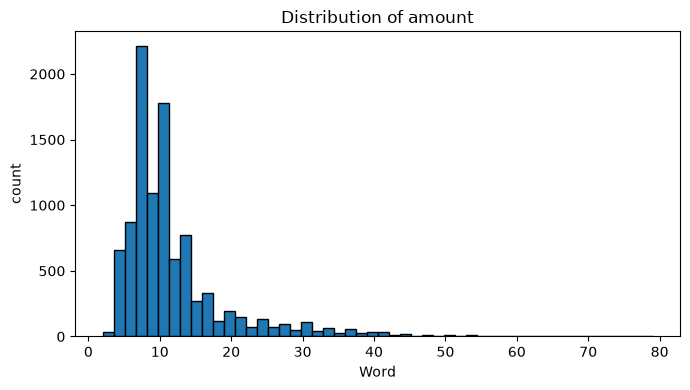

In [23]:
### Vizualize distribution
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df_tr['word_count'], bins=50, edgecolor='black')
ax.set_xlabel('Word')
ax.set_ylabel('count')
ax.set_title('Distribution of amount')
plt.tight_layout()
plt.show()

My understanding of Step 4 is that we are performing feature engineering by calculating the number of characters and words in each message and storing these measurements in two separate columns: char_length and word_count.

By examining the output of the describe() method, I noticed that the standard deviation of character length is approximately six times greater than that of word count. However, I am uncertain about how to interpret this difference. It may indicate that character lengths exhibit greater variability than word counts.

## Step 5 — Analyse Unusual Messages

**Estimated time:** 10 minutes

### 5.1. Objective

Investigate messages that are unusually short or long,
and identify empty or whitespace-only messages.

### 5.2. Methods

- `nsmallest()`
- `nlargest()`
- `sort_values()`

### 5.3. Required Analysis

| Investigation | Required output |
|---|---|
| Five shortest messages | Text and intent labels |
| Five longest messages | Text and intent labels |
| Empty messages | Count |
| Whitespace-only messages | Count |

### 5.4. Interpretation

Investigate whether very short messages provide sufficient
information to identify the customer's intent reliably.

For example, a message containing only "card" would be
difficult to classify accurately.

### 5.5. AI Engineering Connection

In our eventual API, ambiguous or insufficiently informative
requests may require human review rather than an automatic
response.

In [24]:
###Smallest and largest messages
df_tr['char_length'].value_counts(sort=1,ascending=True)

char_length
221      1
336      1
313      1
228      1
295      1
      ... 
37     240
42     246
36     248
41     257
43     261
Name: count, Length: 272, dtype: int64

In [25]:
print('Messages with the smallest char_length:')
df_tr.nsmallest(5,'char_length')[
    ['text','label','char_length','word_count']
]

Messages with the smallest char_length:


,text,label,char_length,word_count
2294,Can I top up?,60,13,4
4003,The card PIN?,38,13,3
4046,wheres my pin,38,13,3
4889,Lost password,44,13,2
5313,phone is gone,42,13,3


In [26]:
print('Messages with the longest char_length:')
df_tr.nlargest(5,'char_length')[
    ['text','label','char_length','word_count']
]

Messages with the longest char_length:


,text,label,char_length,word_count
3917,Hearing back from us regarding your important ...,68,433,79
3934,Hearing about your verification results from u...,68,422,75
7310,Hi! I'm a university student studying abroad a...,64,409,78
3905,You will hear back from us about your verifica...,68,381,70
3910,It can take between 10 minutes to an hour befo...,68,377,70


In [27]:
df_tr['char_length'].sort_values(ascending=False).sample(5)

1618    34
4243    33
5421    27
3926    37
2214    24
Name: char_length, dtype: int64

In [28]:
### Empty mask
empty_mask = df_tr['text'].str.strip() == ''
print(f"Whitespace-only utterances: {empty_mask.sum()}")

df_tr[~empty_mask].head()

Whitespace-only utterances: 0


,text,label,char_length,word_count
0,I am still waiting on my card?,11,30,7
1,What can I do if my card still hasn't arrived ...,11,60,13
2,I have been waiting over a week. Is the card s...,11,58,12
3,Can I track my card while it is in the process...,11,59,13
4,"How do I know if I will get my card, or if it ...",11,54,15


In [29]:
### Empty whitespaces only questions
col = df_tr['text'].astype(str)
empty_or_ws = col.str.strip('').eq('')
count = empty_or_ws.sum()
print(f'Empty or whitespace-only rows in Test Data: {count}')

Empty or whitespace-only rows in Test Data: 0


In [30]:
empty_count = df_tr['text'].eq('').sum()
whitespace_count = (
    df_tr['text'].str.strip().eq('')
    & df_tr['text'].ne('')
).sum()
print('Empty count:',empty_count)
print('Whitespace count:',whitespace_count)

Empty count: 0
Whitespace count: 0


From my perspective, in some cases, a few words are sufficient to express a user's question. In other cases, however, additional details are necessary because of the circumstances, background information, or specific events that have occurred.

To illustrate my understanding, consider the difference between going to a grocery store to buy instant udon noodles and visiting a Japanese restaurant to order a customised bowl of ramen. In the latter case, you might need to specify your preferred ingredients, explain which ingredients you dislike, and even describe previous negative experiences.

# VS

### Observation: Message-Length Variability

Customer messages may vary in length depending on the
amount of contextual information required to express
a particular intent.

Some users can communicate their requests in a few words,
while others provide background information, specific
circumstances, and additional details.

However, longer messages do not necessarily represent
more complex problems. Message length may also depend
on individual communication styles.

This hypothesis requires further investigation through
intent-level analysis and manual examination of messages.

## Step 6 — Message Lengths by Intent

**Estimated time:** 10–15 minutes  
**Priority:** Optional extension

### 6.1. Objective

Compare the mean and median word counts across different
intent categories.

Investigate whether certain banking problems require
longer explanations than others.

### 6.2. Methods

- `groupby()`
- `agg()`
- `sort_values()`

### 6.3. Expected Output

| Intent | Sample count | Mean words | Median words |
|---|---:|---:|---:|
| Intent A | | | |
| Intent B | | | |
| Intent C | | | |

### 6.4. Analysis

Compare the results across intent categories and investigate
whether certain intents tend to have longer messages than others.

**Note:** This is an optional extension rather than a mandatory
requirement of the original Notion assignment.

In [31]:
df_tr.groupby(['label'])['word_count'].agg(['count','mean','median']).reset_index().sort_values(by=['count'],ascending=False)

,label,count,mean,median
15,15,187,13.962567,12.0
28,28,182,15.989011,12.0
6,6,181,14.237569,13.0
75,75,180,15.283333,12.0
19,19,177,14.152542,11.0
...,...,...,...,...
41,41,82,10.743902,9.0
18,18,61,10.360656,10.0
10,10,59,7.474576,8.0
72,72,41,9.365854,8.0


In [32]:
### Obtain label names
label_names = train_data.features['label'].names
label_names[:5]

['activate_my_card',
 'age_limit',
 'apple_pay_or_google_pay',
 'atm_support',
 'automatic_top_up']

In [33]:
### Label mapping
label_mapping = dict(enumerate(label_names))
label_mapping

{0: 'activate_my_card',
 1: 'age_limit',
 2: 'apple_pay_or_google_pay',
 3: 'atm_support',
 4: 'automatic_top_up',
 5: 'balance_not_updated_after_bank_transfer',
 6: 'balance_not_updated_after_cheque_or_cash_deposit',
 7: 'beneficiary_not_allowed',
 8: 'cancel_transfer',
 9: 'card_about_to_expire',
 10: 'card_acceptance',
 11: 'card_arrival',
 12: 'card_delivery_estimate',
 13: 'card_linking',
 14: 'card_not_working',
 15: 'card_payment_fee_charged',
 16: 'card_payment_not_recognised',
 17: 'card_payment_wrong_exchange_rate',
 18: 'card_swallowed',
 19: 'cash_withdrawal_charge',
 20: 'cash_withdrawal_not_recognised',
 21: 'change_pin',
 22: 'compromised_card',
 23: 'contactless_not_working',
 24: 'country_support',
 25: 'declined_card_payment',
 26: 'declined_cash_withdrawal',
 27: 'declined_transfer',
 28: 'direct_debit_payment_not_recognised',
 29: 'disposable_card_limits',
 30: 'edit_personal_details',
 31: 'exchange_charge',
 32: 'exchange_rate',
 33: 'exchange_via_app',
 34: 'extr

In [ ]:
df_tr['intent_name'] = df_tr['label'].map(label_mapping)
df_tr.head()

,text,label,char_length,word_count,intent_name
0,I am still waiting on my card?,11,30,7,card_arrival
1,What can I do if my card still hasn't arrived ...,11,60,13,card_arrival
2,I have been waiting over a week. Is the card s...,11,58,12,card_arrival
3,Can I track my card while it is in the process...,11,59,13,card_arrival
4,"How do I know if I will get my card, or if it ...",11,54,15,card_arrival


In [35]:
### Group by Intent_name
df_tr.groupby('intent_name')['word_count'].agg(['count','mean','median']).reset_index().sort_values(by='count',ascending=False).head()

,intent_name,count,mean,median
16,card_payment_fee_charged,187,13.962567,12.0
29,direct_debit_payment_not_recognised,182,15.989011,12.0
7,balance_not_updated_after_cheque_or_cash_deposit,181,14.237569,13.0
75,wrong_amount_of_cash_received,180,15.283333,12.0
20,cash_withdrawal_charge,177,14.152542,11.0


In [39]:
df_tr["sample_id"] = df_tr.index

In [40]:
#Processed data to csv file
df_tr.to_csv('../data/processed/banking77_train_eda.csv', index=False)

## Step 7 — Write Three Meaningful Findings

### Finding 1 — Intent Categories and Message Ambiguity

- **Observation:** The dataset contains 77 distinct intent
  categories representing different banking problems.

- **Evidence:** The message "I am still waiting on my card?"
  belongs to label 11 (card_arrival), whereas the message
  "Is it possible for me to change my PIN number?"
  belongs to label 21 (change_pin).

- **Engineering implication:** The system must distinguish
  between 77 different customer intents. Although some
  messages clearly express an intent, others may contain
  insufficient contextual information. Ambiguous requests
  may require clarification or human review.


### Finding 2 — Class Distribution and Imbalance

- **Observation:** The training dataset exhibits an uneven
  distribution of samples across intent categories.

- **Evidence:** Label 15 contains 187 samples, whereas
  label 23 contains only 35 samples. The imbalance ratio
  between these classes is approximately 5.34.

- **Engineering implication:** Unequal class distributions
  may cause the classifier to perform better on frequent
  intents than on minority intents. Stratified validation,
  macro-F1 scores and per-class evaluation should be used
  to investigate this potential issue.


### Finding 3 — Missing Values and Duplicate Entries

- **Observation:** No missing values or exact duplicate
  entries were identified in the text column.

- **Evidence:**
    - Missing text values: 0
    - Duplicate text entries: 0

- **Engineering implication:** No immediate missing-text
  imputation or exact-duplicate removal is required.
  However, additional checks for empty messages,
  near-duplicates and inconsistent labels are necessary
  to establish overall data quality.